In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Make results reproducible
np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create sample data for 500 applicants
n = 500

income = np.random.randint(15000, 150001, n)
loan = np.random.randint(20000, 500001, n)
credit = np.random.choice([0, 1], n, p=[0.25, 0.75])

# Generate sample loan outcomes
approval_probability = (
    0.15
    + 0.55 * credit
    + 0.15 * (income > 50000)
    - 0.10 * (loan > 250000)
)

approval_probability = np.clip(approval_probability, 0.05, 0.95)

status = np.random.binomial(1, approval_probability)

# Create DataFrame
df = pd.DataFrame({
    "ApplicantIncome": income,
    "LoanAmount": loan,
    "CreditHistory": credit,
    "LoanStatus": status
})

# Save dataset as CSV
df.to_csv("loan_data.csv", index=False)

print("Dataset created successfully!")
print("Total applicants:", len(df))

df.head()

Dataset created successfully!
Total applicants: 500


,ApplicantIncome,LoanAmount,CreditHistory,LoanStatus
0,136958,375540,1,0
1,146932,212714,1,1
2,118694,227611,0,1
3,134879,303876,0,1
4,125268,279747,1,1


In [3]:
df.shape

(500, 4)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   ApplicantIncome  500 non-null    int32
 1   LoanAmount       500 non-null    int32
 2   CreditHistory    500 non-null    int64
 3   LoanStatus       500 non-null    int32
dtypes: int32(3), int64(1)
memory usage: 9.9 KB


In [5]:
df.isnull().sum()

ApplicantIncome    0
LoanAmount         0
CreditHistory      0
LoanStatus         0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,ApplicantIncome,LoanAmount,CreditHistory,LoanStatus
count,500.000000,500.000000,500.000000,500.000000
mean,84451.150000,256904.952000,0.760000,0.626000
std,40807.002592,138733.079831,0.427511,0.484348
min,15769.000000,20404.000000,0.000000,0.000000
25%,46960.500000,140607.000000,1.000000,0.000000
50%,85314.500000,265503.000000,1.000000,1.000000
75%,121363.500000,379863.750000,1.000000,1.000000
max,149633.000000,499920.000000,1.000000,1.000000


In [8]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Check missing values
print(df.isnull().sum())

print("Data cleaning check complete!")

ApplicantIncome    0
LoanAmount         0
CreditHistory      0
LoanStatus         0
dtype: int64
Data cleaning check complete!


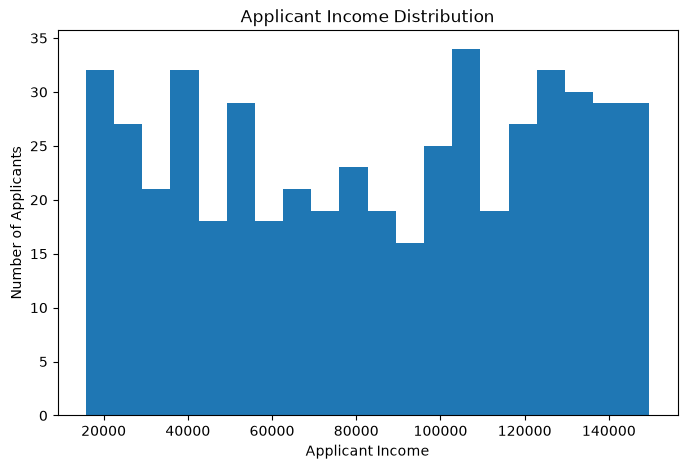

In [9]:
plt.figure(figsize=(8, 5))
plt.hist(df["ApplicantIncome"], bins=20)
plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")
plt.show()

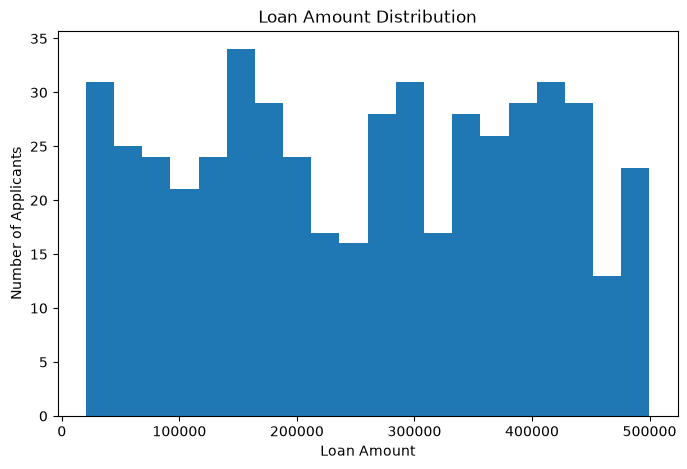

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(df["LoanAmount"], bins=20)
plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applicants")
plt.show()

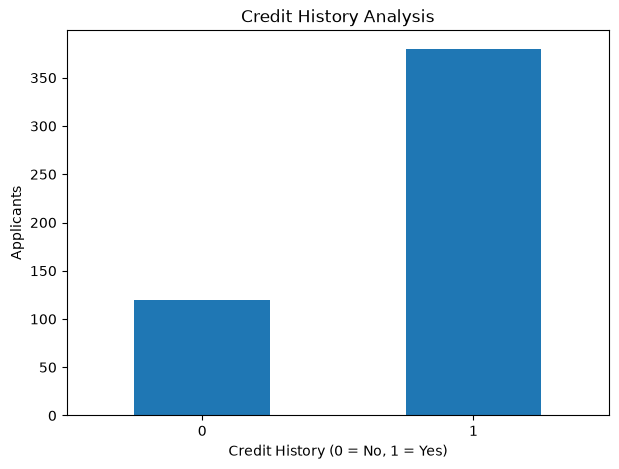

In [11]:
df["CreditHistory"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 5)
)
plt.title("Credit History Analysis")
plt.xlabel("Credit History (0 = No, 1 = Yes)")
plt.ylabel("Applicants")
plt.xticks(rotation=0)
plt.show()

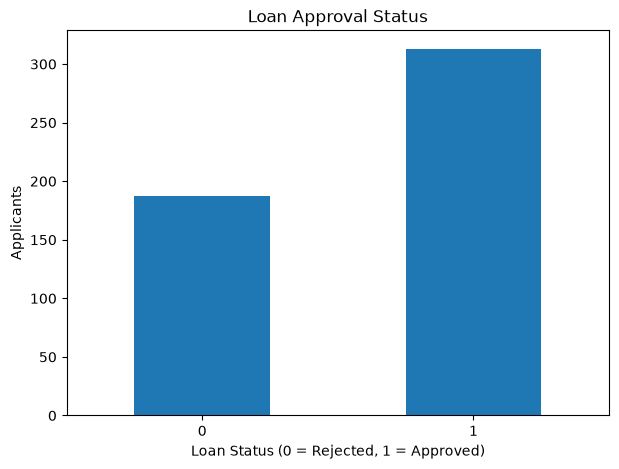

In [12]:
df["LoanStatus"].value_counts().sort_index().plot(
    kind="bar", figsize=(7, 5)
)
plt.title("Loan Approval Status")
plt.xlabel("Loan Status (0 = Rejected, 1 = Approved)")
plt.ylabel("Applicants")
plt.xticks(rotation=0)
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

X = df[["ApplicantIncome", "LoanAmount", "CreditHistory"]]
y = df["LoanStatus"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 0.82

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.59      0.71        37
           1       0.80      0.95      0.87        63

    accuracy                           0.82       100
   macro avg       0.84      0.77      0.79       100
weighted avg       0.83      0.82      0.81       100


Confusion Matrix:
[[22 15]
 [ 3 60]]


In [14]:
import pickle

with open("credit_risk_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")

Model saved successfully!


In [15]:
new_applicant = pd.DataFrame([{
    "ApplicantIncome": 50000,
    "LoanAmount": 150000,
    "CreditHistory": 1
}])

prediction = model.predict(new_applicant)

if prediction[0] == 1:
    print("Predicted Status: Approved")
else:
    print("Predicted Status: Rejected")

Predicted Status: Approved


In [16]:
# Predict risk category for applicants

df["PredictedLoanStatus"] = model.predict(
    df[["ApplicantIncome", "LoanAmount", "CreditHistory"]]
)

df["RiskCategory"] = np.where(
    (df["CreditHistory"] == 0) |
    ((df["LoanAmount"] > 250000) & (df["ApplicantIncome"] < 40000)),
    "High Risk",
    "Low Risk"
)

print(df[["ApplicantIncome", "LoanAmount",
          "CreditHistory", "RiskCategory"]].head(10))

   ApplicantIncome  LoanAmount  CreditHistory RiskCategory
0           136958      375540              1     Low Risk
1           146932      212714              1     Low Risk
2           118694      227611              0    High Risk
3           134879      303876              0    High Risk
4           125268      279747              1     Low Risk
5            69886      111362              1     Low Risk
6           102498      443570              1     Low Risk
7           127727      295987              1     Low Risk
8           141324      134065              1     Low Risk
9            31023      353870              0    High Risk


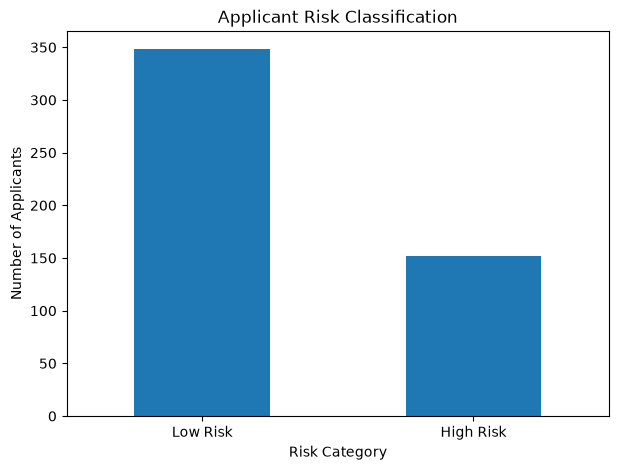

In [17]:
df["RiskCategory"].value_counts().plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Applicant Risk Classification")
plt.xlabel("Risk Category")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.show()

In [18]:
df.to_csv("credit_risk_analysis_results.csv", index=False)

print("Analysis results saved successfully!")

Analysis results saved successfully!
